# Practical 0 - Python Primer for Advanced Transport Phenomena

### Starter for students coming from MATLAB

This notebook is optional reference material. It serves as a stater for basic coding in python, assuming a familiarity with Matlab. It covers a broad range of basis. 

Matlab is relatively close to Python so nothing should be difficult. What matters is the logic of programming and not the syntax of a specific language.

Nothing here is specific to transport phenomena, it is pure Python

## 0.1 Common differences

Here is the most common major differences, keep this table in mind to start easier.

| | MATLAB | Python |
|---|---|---|
| Indexing | 1-based: `A(1)` is the first element | 0-based: `a[0]` is the first element |
| Block delimiters | `for ... end`, `if ... end` | indentation, no `end` keyword |
| Range | `1:n` includes both 1 and n | `range(n)` gives `0, 1, ..., n-1`, n is excluded |
| Copying a variable | `b = a;` copies the data | `b = a` copies only the reference (section 0.9) |
| Elementwise vs. matrix ops | `*` is matrix product, `.*` is elementwise | `*` between NumPy arrays is already elementwise |

Everything below unpacks these five points, plus the ordinary syntax (printing, functions, plotting) you'll need.

-----------------------------------------------------------------------------------------------------------------------------------------------------------

## 0.2 Comments and printing

Python comments start with `#` (MATLAB: `%`). 

To display something, Python uses `print(...)` instead of `disp`/`fprintf`. 

For formatted messages mixing text and numbers, an f-string (`f"..."` with `{variable}` placeholders) is the equivalent of MATLAB's `sprintf`/`fprintf` format specifiers. You write the variable name directly in the braces; no `%f`/`%d` placeholders and separate argument list are needed.

In [1]:
# a comment, like % in MATLAB

Co = 0.42
Di = 0.125

print("Hello, ATP!")
print(f"Co={Co}, Di={Di}")          # like fprintf('Co=%f, Di=%f', Co, Di)
print(f"Co={Co:.4f}, Di={Di:.4f}")  # :.4f controls the number of decimals shown

Hello, ATP!
Co=0.42, Di=0.125
Co=0.4200, Di=0.1250


---------



## 0.3 Variables, types, and arithmetic

Like MATLAB, Python is dynamically typed: 
You never declare a variable's type or pre-size it (`n_points = 21` just works). 

Python distinguishes `int` (whole numbers) from `float` (decimals). This matters because `/` between two numbers always returns a float, e.g. `7 / 2` is `3.5`, not truncated. Use `//` for integer (floor) division, and `%` for the remainder. The latter is exactly what you'll use for "do something every 25 steps": `if m % 25 == 0`.

Operators `+ - * / **` work as expected; `**` is power (MATLAB `^`). Comparisons `==`, `!=` (MATLAB `~=`), `<`, `>`, `<=`, `>=` are otherwise identical to MATLAB.


In [3]:
npts = 21     # int
L = 2.0           # float

print(type(npts), type(L))
print(7 / 2)       # 3.5, true division
print(7 // 2)      # 3, floor division
print(7 % 2)       # 1, remainder
print(2 ** 3)      # 8, power (MATLAB: 2^3)

<class 'int'> <class 'float'>
3.5
3
1
8


-----------------------------------------------------------------------------------------------------------------------------------------------------------

## 0.4 No `end`: Python uses indentation

MATLAB closes every block explicitly:

```matlab
for i = 1:5
    disp(i)
end
```

Python has no closing keyword at all. Instead, a line ending in `:` opens a block, and everything indented underneath (by convention, 4 spaces) belongs to it. The block ends the moment a line returns to the previous indentation level:

```python
for i in range(5):
    print(i)
# this line is NOT indented, so it's already outside the loop
```

This is not a style preference. Inconsistent indentation is a syntax error (`IndentationError`), or worse, it silently changes what belongs to the loop, the `if`, or the function. Whenever you copy and paste code, check that the indentation survived the trip.

In [5]:
for i in range(5):
 x = i * 2
 print(x)        # indented, inside the loop, runs 5 times

print("done 1")       # not indented, runs once, after the loop
    

0
2
4
6
8
done 1


-----------------------------------------------------------------------------------------------------------------------------------------------------------

## 0.5 Indexing starts at 0, and ranges exclude their endpoint

In MATLAB, `A(1)` is the first element and `A(n)` is the last of an `n`-element array, and a loop `for i = 1:n` visits every index. 

In Python, the first element is at index `0` and the last at index `n-1`. `range(n)` produces `0, 1, ..., n-1`, exactly `n` values, with the endpoint `n` itself excluded.

Negative indices count from the end: `a[-1]` is the last element, `a[-2]` the second to last. There is no direct MATLAB equivalent, and it becomes very convenient once it clicks.

Slicing `a[start:stop]` extracts a sub-array, again excluding `stop`. This is the single most common source of off-by-one confusion when translating a MATLAB `A(start:stop)`, which is inclusive on both ends.

The practical consequence for this whole course: a MATLAB loop `for i = 2:np-1` (interior points, skipping the first and last of an `np`-element array) becomes, in Python, `for i in range(1, n_points - 1)`. Start one earlier, `1` instead of `2`, because index `0` is now the first point. The stop value needs no further correction, since `range`'s exclusive endpoint already does that job.

In [15]:
import numpy as np

a = np.array([10, 20, 30, 40, 50])   # 5 elements, indices 0..4
b= [1,2,3,4,5]
print(a[0])      # 10, first element  (MATLAB: a(1))
print(a[-1])     # 50, last element   (MATLAB: a(5), or a(end))
print(a[1:-1])   # [20 30 40]         (MATLAB: a(2:4))
print(a[2:])     # [30 40 50]         (MATLAB: a(3:end))
print(a[:-2])    # [10 20 30]         (MATLAB: a(1:end-2))

print(a[0:-1:2])
print(a[::-1])


# Side by side loop equivalence:
# MATLAB:  for i = 2:4        (visits indices 2, 3, 4 of a 5-element array)
# Python:
for i in range(1, 4):          # visits indices 1, 2, 3, the same three middle elements
    print(i, a[i])

        # visits indices 1, 2, 3, the same three middle elements
print(a*2)
print(b*2)

for i in a:
    y=i*2
    print(y)

10
50
[20 30 40]
[30 40 50]
[10 20 30]
[10 30]
[50 40 30 20 10]
1 20
2 30
3 40
[ 20  40  60  80 100]
[1, 2, 3, 4, 5, 1, 2, 3, 4, 5]
20
40
60
80
100


-----------------------------------------------------------------------------------------------------------------------------------------------------------

## 0.6 `if` / `elif` / `else`

Identical logic to MATLAB's `if / elseif / else / end`, just spelled `elif`, using `:` and indentation instead of `end`, and `!=` instead of `~=`.

In [16]:
Co = 1.3

if Co < 1:
    print("stable")
elif Co == 1:
    print("marginal")
else:
    print("unstable")

unstable


-----------------------------------------------------------------------------------------------------------------------------------------------------------

## 0.7 Functions

MATLAB: `function y = f(x) ... y = x^2; end`. Python: `def f(x): ... return x**2`. 

In Python there is no `end`, and the return value must be given explicitly with `return` (MATLAB infers it from the declared output name).

In [17]:
def square(x):
    '''Return the square of x.'''
    y=x*x
    return y

def courant_number(u, dt, h):
    return u * dt / h

print(square(4.5))
print(courant_number(u=1.0, dt=0.05, h=0.1))

20.25
0.5


-----------------------------------------------------------------------------------------------------------------------------------------------------------

## 0.8 NumPy arrays: Python's equivalent of MATLAB vectors and matrices

MATLAB's fundamental data type is the matrix; every variable is one by default. Python has no such built-in. Its native `list` (`[1, 2, 3]`) is a generic container that does not support elementwise math: `[1,2,3] + [10,20,30]` concatenates into a 6-element list, it does not add elementwise. For numerical work we instead use NumPy, imported by convention as `np`:

```python
import numpy as np
```


The main array-creation functions you'll use, with their MATLAB equivalents:

| MATLAB | NumPy |
|---|---|
| `zeros(n,1)` | `np.zeros(n)` |
| `linspace(a,b,n)` | `np.linspace(a,b,n)` (same signature, inclusive of both ends) |
| `sin`, `exp`, `sqrt`, `pi` | `np.sin`, `np.exp`, `np.sqrt`, `np.pi` |

Important operator difference: in MATLAB, `*` between two vectors can mean matrix multiplication, forcing you to write `.*` for elementwise multiplication. In NumPy, `*` between arrays is always elementwise, there is no separate "dot star" operator needed. Real matrix multiplication, when you need it, is `@` or `np.dot`.

In [23]:
a = np.array([1, 2, 3])
b = np.array([10, 20, 30])

print(a + b)     # [11 22 33], elementwise, like MATLAB's a + b
print(a * b)     # [10 40 90], elementwise! (MATLAB would need a .* b)
print(a ** 2)    # [1 4 9]

print(np.zeros(5))
print(np.linspace(0.0, 2.0, 5))

print(np.concatenate([a,b]))
print(np.append(a,4))
      


[11 22 33]
[10 40 90]
[1 4 9]
[0. 0. 0. 0. 0.]
[0.  0.5 1.  1.5 2. ]
[ 1  2  3 10 20 30]
[1 2 3 4]


-----------------------------------------------------------------------------------------------------------------------------------------------------------

## 0.9 Assignment does not copy

In MATLAB, `b = a;` copies the data. If you then modify `b`, `a` is untouched. In Python, `b = a` for a NumPy array does not copy anything. It makes `b` a second name pointing at the same array in memory. Modify `b`, and `a` changes too, silently, with no error.

In [24]:
a = np.array([1, 2, 3])
b = a            # not a copy, same array under two names

b[0] = 99
print(a)         # [99  2  3], a changed too, even though we only touched b

[99  2  3]


To get MATLAB's copy-on-assignment behavior, you must ask for it explicitly with `.copy()`.

In [25]:
a = np.array([1, 2, 3])
b = a.copy()     # genuinely independent copy, like MATLAB's b = a;

b[0] = 99
print(a)         # [1 2 3], unaffected
print(b)         # [99 2 3], only b changed

[1 2 3]
[99  2  3]


Every explicit time-stepping scheme in this course follows the same pattern: save the old solution, then overwrite the current one, using the old values as the recipe. In MATLAB, `f_old = f;` at the top of a time step just works. In Python, if you write `f_old = f` without `.copy()` and then start overwriting entries of `f` in a loop, `f_old` silently changes underneath you mid-loop, and the explicit scheme quietly turns into something else: no crash, no warning, just a wrong answer.

Whenever you see `f_old = f.copy()` in the practicals, this is why. It is the single most important line in every scheme you will write this semester.

--------------------

## 0.10 Plotting with Matplotlib

For visualizing results we use Matplotlib.

Matplotlib's `pyplot` interface, imported as `plt`. 

`plot`, `xlabel`, `ylabel`, `legend`, `title` all exist with nearly the same names and arguments as in MATLAB.

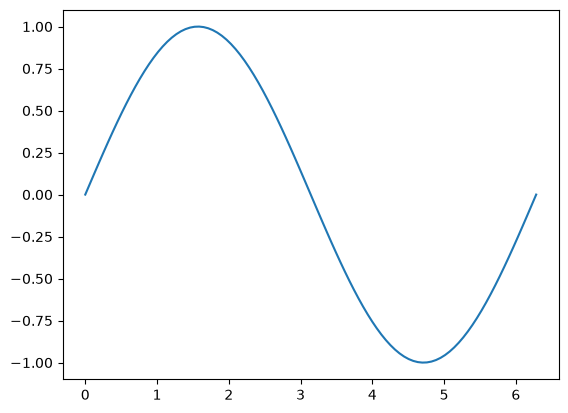

In [27]:
import matplotlib.pyplot as plt

x = np.linspace(0, 2*np.pi, 100)
y = np.sin(x)

plt.plot(x, y)   # MATLAB: plot(x, y, 'LineWidth', 2)
plt.show()

-----------------------------------------------------

## 0.11 Exercise

Before going back to the practical, try this on your own in the empty cell below

1. Create a NumPy array `x` of 200 points evenly spaced between `0` and `4`.
2. Compute $f(x) = \exp(x) \sin(2\pi x)$ Using an array y as the f(x)
3. Plot `y` against `x`, with axis labels.

That's the Python-specific core. Everything in the practicals from here on is transport phenomena and numerical methods, the part you already know how to reason about.